**Name:** Nawaf Mohammed Alghamdi

**Student ID:** 2240007352

# **Lab 9 - Morphological Operations**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Erosion2.jpg'

# **Erosion Operations**

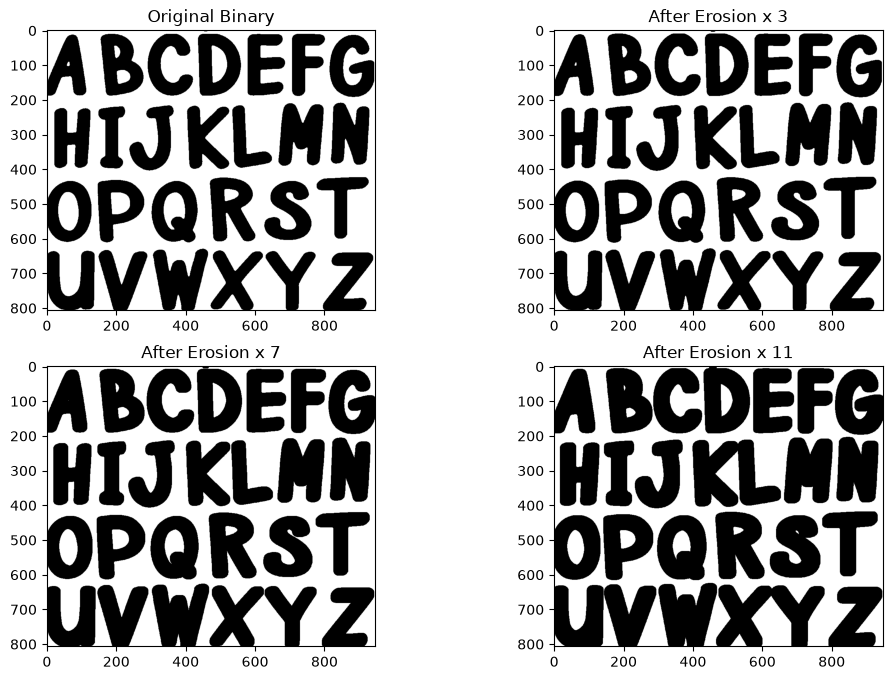

In [2]:

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method works well for varying light)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define a 3x3 kernel (all ones), you can define kernel of size 5x5, 7x7, ... any odd x odd
# Larger kernels lead to more aggressive erosion

kernel3 = np.ones((3, 3), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

# 4. Apply erosion
# 'iterations' determines how many times the operation is repeated,
# ===> You can change iterations values to apply same process multiple times.

eroded_img3 = cv2.erode(binary, kernel3, iterations=1)
eroded_img7 = cv2.erode(binary, kernel7, iterations=1)
eroded_img11 = cv2.erode(binary, kernel11, iterations=1)

# 5. Display comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(eroded_img3, 'gray'), plt.title('After Erosion x 3')
plt.subplot(2, 2, 3), plt.imshow(eroded_img7, 'gray'), plt.title('After Erosion x 7')
plt.subplot(2, 2, 4), plt.imshow(eroded_img11, 'gray'), plt.title('After Erosion x 11')


plt.show()


# **Dilation Operations**

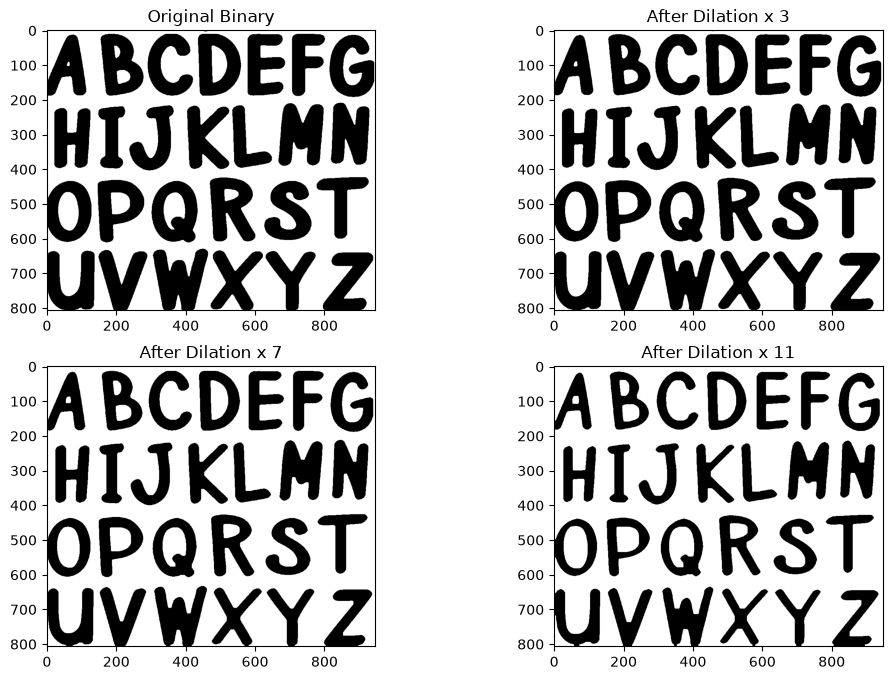

In [3]:

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method works well for varying light)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define a 3x3 kernel (all ones), you can define kernel of size 5x5, 7x7, ... any odd x odd
# Larger kernels lead to more aggressive erosion

kernel3 = np.ones((3, 3), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

# 4. Apply erosion
# 'iterations' determines how many times the operation is repeated,
# ===> You can change iterations values to apply same process multiple times.

eroded_img3 = cv2.dilate(binary, kernel3, iterations=1)
eroded_img7 = cv2.dilate(binary, kernel7, iterations=1)
eroded_img11 = cv2.dilate(binary, kernel11, iterations=1)

# 5. Display comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(eroded_img3, 'gray'), plt.title('After Dilation x 3')
plt.subplot(2, 2, 3), plt.imshow(eroded_img7, 'gray'), plt.title('After Dilation x 7')
plt.subplot(2, 2, 4), plt.imshow(eroded_img11, 'gray'), plt.title('After Dilation x 11')


plt.show()


# **Morphological Open Operations**

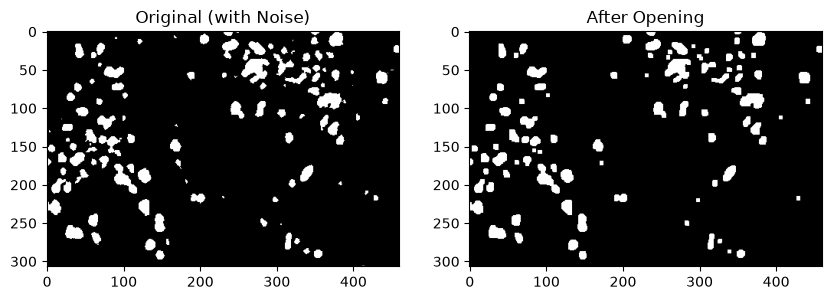

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Open_Closing.jpg'

# 1. Load image and binarize
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define kernel (a 5x5 square is a good starting point)
kernel = np.ones((5, 5), np.uint8)

# 3. Apply Opening
# This is equivalent to: dilate(erode(binary))
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

# 4. Display comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original (with Noise)')
plt.subplot(1, 2, 2), plt.imshow(opening, 'gray'), plt.title('After Opening')
plt.show()


# **Closing Morphological Operation**

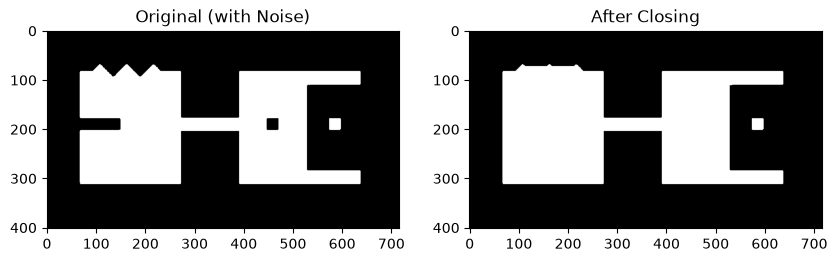

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Opening2.jpg'

# 1. Load image and binarize
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define kernel (a 45x45 square is a good starting point)
kernel = np.ones((45, 45), np.uint8)

# 3. Apply Opening
# Effectively: cv2.erode(cv2.dilate(binary, kernel), kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# 4. Display comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original (with Noise)')
plt.subplot(1, 2, 2), plt.imshow(closing, 'gray'), plt.title('After Closing')
plt.show()


# **Boundaries Extractions**

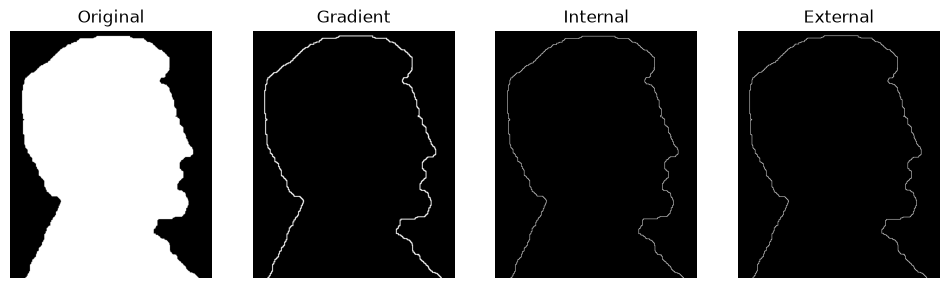

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


imgFile = 'BoundaryExtraction.jpg'
# 1. Load and binarize the image (foreground must be white)
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define a kernel (the size controls boundary thickness)
kernel = np.ones((3, 3), np.uint8)

# 3. Method A: Morphological Gradient (Built-in standard)
gradient = cv2.morphologyEx(binary, cv2.MORPH_GRADIENT, kernel)

# 4. Method B: Internal Boundary (Original - Eroded)
eroded = cv2.erode(binary, kernel)
internal = cv2.subtract(binary, eroded)

# 5. Method C: External Boundary (Dilated - Original)
dilated = cv2.dilate(binary, kernel)
external = cv2.subtract(dilated, binary)

# Visualization
titles = ['Original', 'Gradient', 'Internal', 'External']
images = [binary, gradient, internal, external]

plt.figure(figsize=(12, 4))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.axis('off')
plt.show()

## Task 1 - Morphological operations on Balls.png

Otsu thresholding converts the supplied image to binary. Inverse thresholding makes the dark balls, numbers, and border white foreground so erosion shrinks these features and dilation expands them. A 5 x 5 square kernel is used for all four operations.

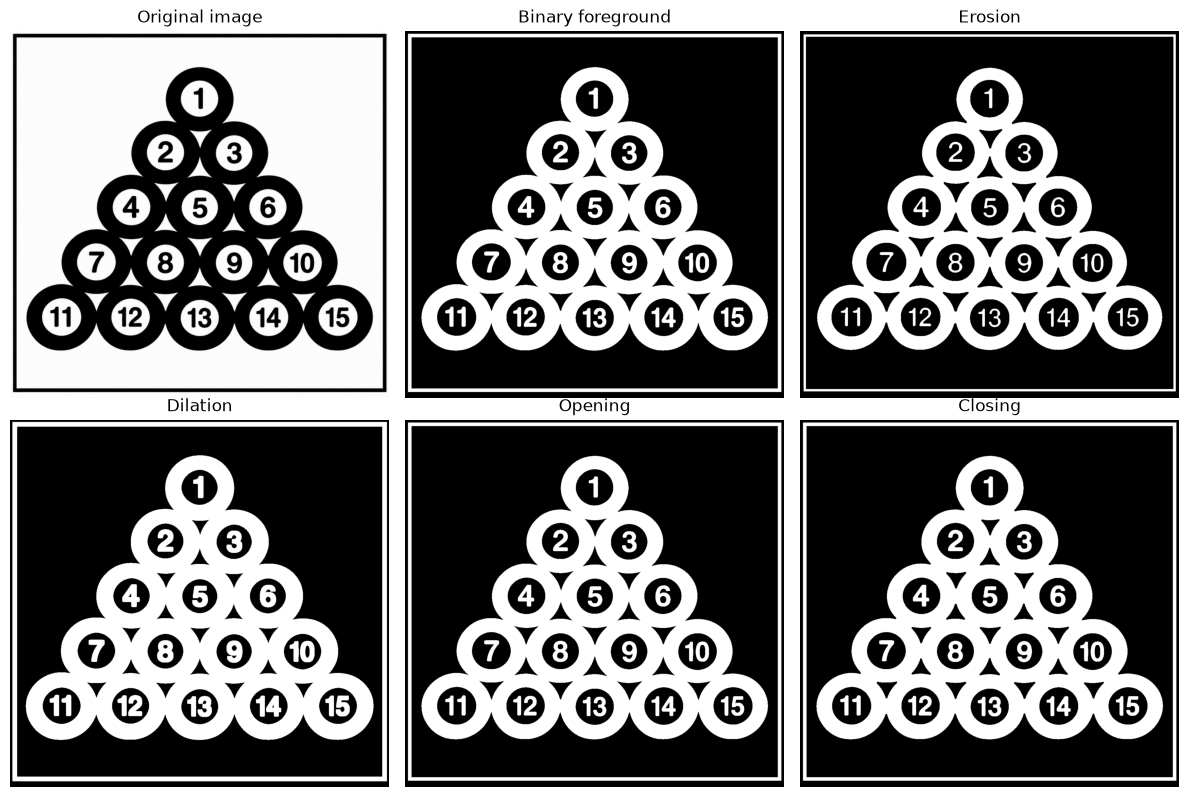

Otsu threshold: 127
Binary foreground    500,374 foreground pixels
Erosion              432,293 foreground pixels
Dilation             567,126 foreground pixels
Opening              500,345 foreground pixels
Closing              501,666 foreground pixels


In [7]:
balls_gray = cv2.imread('Balls.png', cv2.IMREAD_GRAYSCALE)
threshold, balls_binary = cv2.threshold(
    balls_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)
balls_kernel = np.ones((5, 5), np.uint8)
balls_eroded = cv2.erode(balls_binary, balls_kernel)
balls_dilated = cv2.dilate(balls_binary, balls_kernel)
balls_opened = cv2.morphologyEx(balls_binary, cv2.MORPH_OPEN, balls_kernel)
balls_closed = cv2.morphologyEx(balls_binary, cv2.MORPH_CLOSE, balls_kernel)

balls_titles = ['Original image', 'Binary foreground', 'Erosion',
                'Dilation', 'Opening', 'Closing']
balls_images = [balls_gray, balls_binary, balls_eroded,
                balls_dilated, balls_opened, balls_closed]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, title, result in zip(axes.flat, balls_titles, balls_images):
    ax.imshow(result, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

print(f"Otsu threshold: {threshold:.0f}")
for title, result in zip(balls_titles[1:], balls_images[1:]):
    print(f"{title:<18} {np.count_nonzero(result):>9,} foreground pixels")

Erosion thins the ball rings, numbers, and border, while dilation thickens them and narrows the dark gaps. Opening removes small white protrusions and narrow foreground features. Closing fills small dark gaps and smooths narrow indentations. Because the supplied image is already relatively clean and its main objects are large, opening and closing with a 5 x 5 kernel produce subtle changes.

## Task 2 - Structuring element shapes and sizes

Erosion and dilation are compared using square, cross, and ellipse kernels of sizes 3 x 3, 5 x 5, and 7 x 7. Each operation uses one iteration on the same binary image.

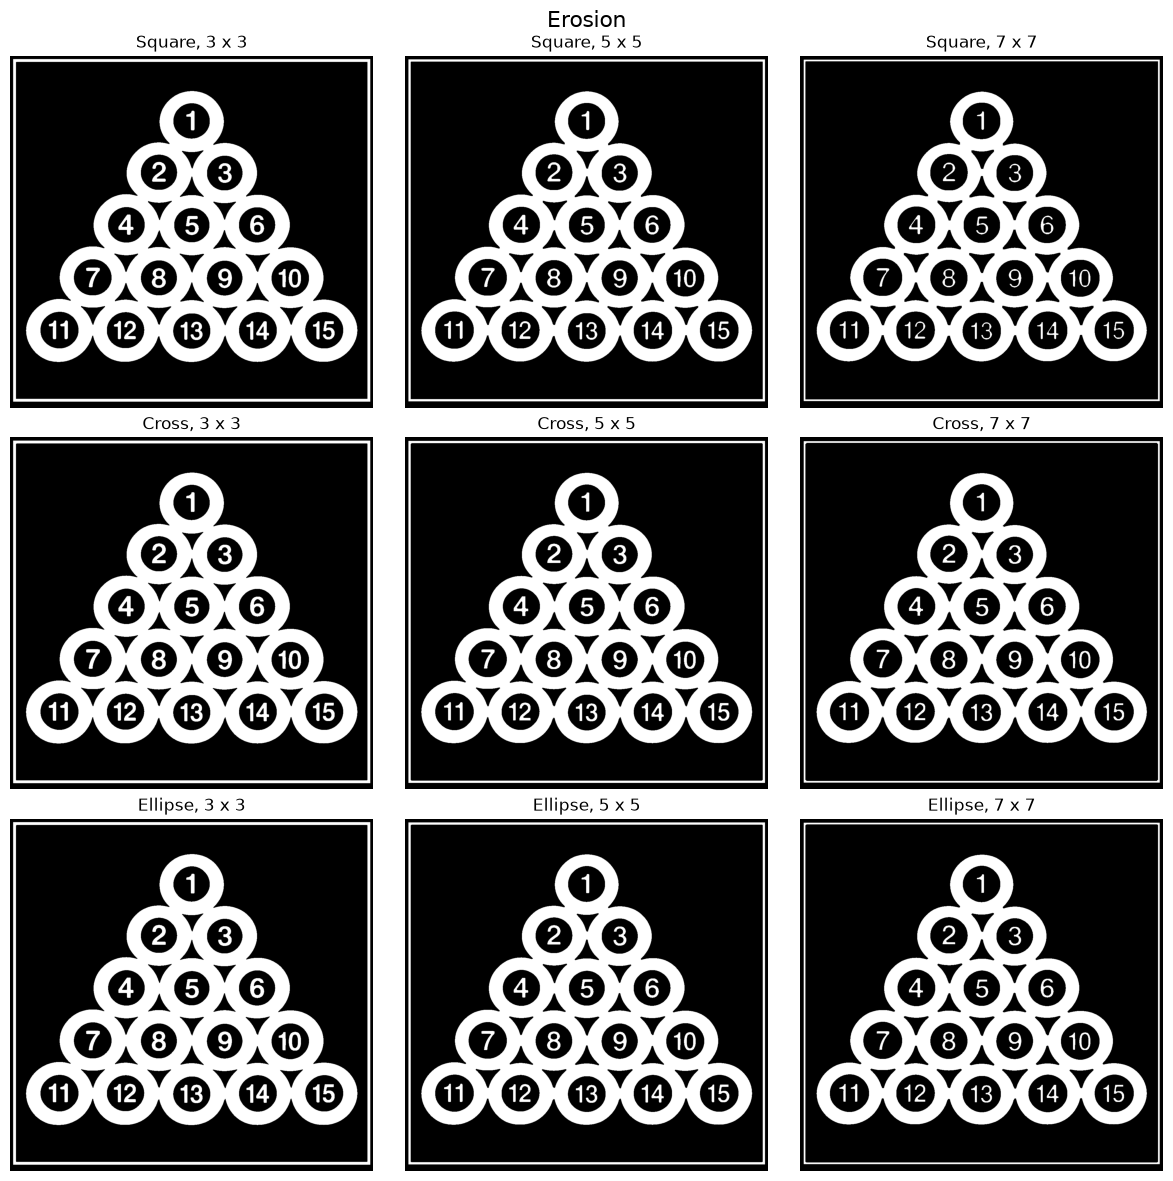

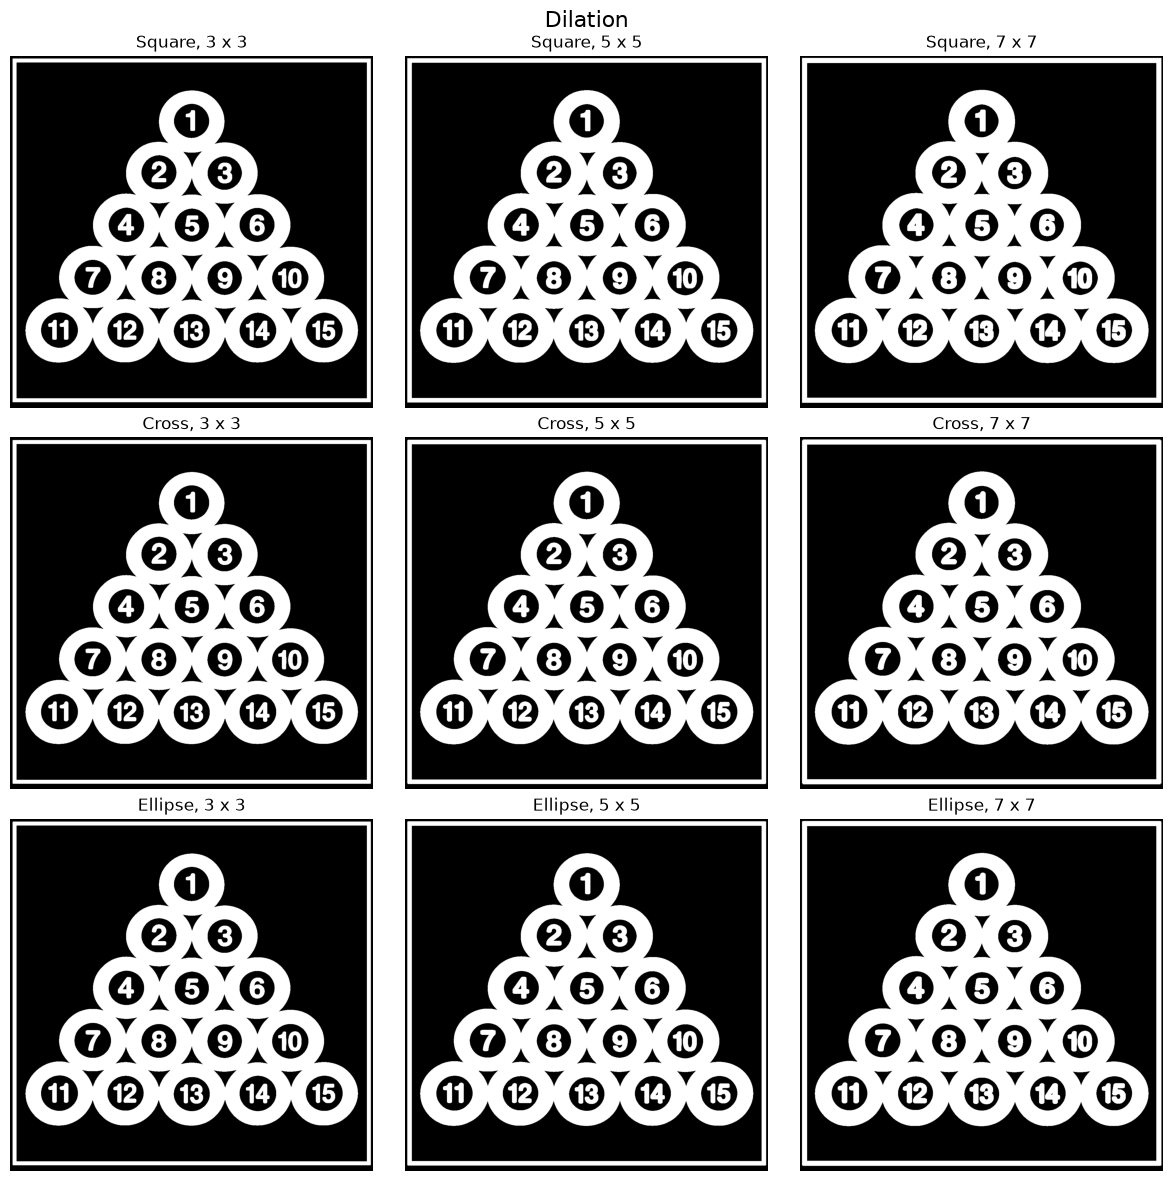

Shape      Size      Erosion pixels   Dilation pixels
Square     3 x 3            466,395           534,094
Square     5 x 5            432,293           567,126
Square     7 x 7            398,085           599,496
Cross      3 x 3            473,108           527,560
Cross      5 x 5            445,935           554,380
Cross      7 x 7            418,852           580,813
Ellipse    3 x 3            473,108           527,560
Ellipse    5 x 5            440,791           559,214
Ellipse    7 x 7            413,345           585,692


In [8]:
kernel_shapes = {
    'Square': cv2.MORPH_RECT,
    'Cross': cv2.MORPH_CROSS,
    'Ellipse': cv2.MORPH_ELLIPSE
}
kernel_sizes = [3, 5, 7]
erosion_results = {}
dilation_results = {}

for shape_name, shape_code in kernel_shapes.items():
    for size in kernel_sizes:
        element = cv2.getStructuringElement(shape_code, (size, size))
        erosion_results[(shape_name, size)] = cv2.erode(balls_binary, element)
        dilation_results[(shape_name, size)] = cv2.dilate(balls_binary, element)

for operation_name, results in [('Erosion', erosion_results),
                                ('Dilation', dilation_results)]:
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    for row, shape_name in enumerate(kernel_shapes):
        for column, size in enumerate(kernel_sizes):
            axes[row, column].imshow(
                results[(shape_name, size)], cmap='gray', vmin=0, vmax=255
            )
            axes[row, column].set_title(f'{shape_name}, {size} x {size}')
            axes[row, column].axis('off')
    fig.suptitle(operation_name, fontsize=16)
    plt.tight_layout()
    plt.show()

print(f"{'Shape':<10} {'Size':<8} {'Erosion pixels':>15} {'Dilation pixels':>17}")
for shape_name in kernel_shapes:
    for size in kernel_sizes:
        eroded_count = np.count_nonzero(erosion_results[(shape_name, size)])
        dilated_count = np.count_nonzero(dilation_results[(shape_name, size)])
        print(f"{shape_name:<10} {str(size) + ' x ' + str(size):<8}"
              f" {eroded_count:>15,} {dilated_count:>17,}")

Increasing kernel size removes more foreground during erosion and adds more during dilation. At a fixed size, the square kernel includes diagonal neighbors and produces the largest area changes. The cross uses only horizontal and vertical arms, so its effects depend more strongly on edge orientation. The ellipse follows curved boundaries more closely, with area changes between the square and cross for this image. OpenCV produces identical cross and ellipse masks at 3 x 3, so their results match at that size. The printed foreground counts quantify changes that can be difficult to see in the full image.